# Nuages de mots

## Imports et stopwords

In [190]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image
from unidecode import unidecode

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Mirei\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [191]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]

#Itération 1 : abréviations des petites annonces, erreurs d'OCR et mots grammaticaux
sw += ["dés", "ecr", "adr", "mod", "fem", "cuis", "etc", "jne", "tne", "ruo", "très", "toute", "peu", "chez", "près"]

# Itération 2 : vocabulaire des petites annonces (immobilier, emploi, ventes) 
sw += ["rue", "prix", "maison", "louer", "demande", "vend", "vendre", "vente", "agence", "avenue", "francs", "notaire", "fille", "gaz", "eau", "cour", "salle", "quart", "bel", "belle", "bon", "bonne", "bons", "grand", "grande"]

# Itération 3 : expressions de temps (mois, jours, heures) 
sw += ["ans", "heures", "mois", "jours", "jour", "soir", "matin", "temps", "hier", "janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"] 
# Itération 3 (suite) : abréviations et erreurs d'OCR restantes, mots grammaticaux 
sw += ["brux", "sal", "jard", "sér", "app", "pet", "com", "cap", "rne", "serv", "chamb", "garn", "pens", "mén", "enf", "pers", "sach", "aveo", "rien", "leurs", "vers", "avant", "suite", "part"]

# Itération 4 : derniers résidus (abréviations, mots généraux, petites annonces) 
sw += ["con", "aven", "ord", "prés", "quelques", "fois", "toujours", "seul", "cent", "demi", "appart", "chambre", "jardin", "contenant"]

# Itération 5 : résidus (OCR, abréviations, temps, petites annonces) 
sw += ["eor", "dom", "mme", "heure", "courant", "moment", "lieu", "garni", "pension", "piano", "beau", "petit", "bas"]

# Itération 6 : mots grammaticaux restants et cohérence des catégories 
# (adresses et offres d'emploi des petites annonces) 
sw += ["elles", "quand", "dès", "devant", "voir", "premier", "première", "chaussée", "boulevard", "place", "femme", "dame", "homme", "jeune"]

# Itération 7 : la liste NLTK étant incomplète, on ajoute celle de spaCy (plus complète) 
# et quelques mots grammaticaux absents des deux listes 
from spacy.lang.fr.stop_words import STOP_WORDS 
sw += list(STOP_WORDS) 
sw += ["beaucoup", "trop", "oui", "jamais"] 
# Itération 7 (suite) : derniers termes des petites annonces 
sw += ["ecrire", "écrire", "occasion", "villa", "rentier", "réf", "hom", "hommes", "petite", "gros", "tel", "tél", "cond", "refer", "réfer", "places", "franc", "franç"]

sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [192]:
# Choisir une année
year = 1914

In [193]:
# Lister les fichiers de cette année
data_path = '../data'
txt_path = '../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and f.split("_")[2].split("-")[0] == str(year)]
len(txts)

100

In [194]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [195]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [196]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"tin drame de famille. — Tué,pâr:riJh père, • ^. ETCHARPE&. SKUN6S VERITABLES, ' Un‘des chanteurs français, lefi -jribs pôpu-.; 4#-cfiotx, &)%’mitais'; LILIV; m~, rivale, : ïàli^;-HtfiW'‘Pottî;i)lo?}cq"

In [197]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [198]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"tin drame de famille. — Tué,pâr:riJh père, • ^. ETCHARPE&. SKUN6S VERITABLES, ' Un‘des chanteurs français, lefi -jribs pôpu-.; 4#-cfiotx, &)%’mitais'; LILIV; m~, rivale, : ïàli^;-HtfiW'‘Pottî;i)lo?}cqnniuiço^^e.ift,€nf6j.ae.: c J ‘ ■ 1 - - * . * wiaw4 litni* /ïnr\\-û Æûa -nttf/irtïT^lJl^flC .1 1 • Fragson,* est mort liier,dans des cireaitatahces y ' tragiques. Il a été tué d’un coup de revolver !* ‘par son père, un vieillard;-de': 84 fttavfi’ant .^rftge-a altéré les facultés 1 meot&lesr ‘ ' ' 1 •"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [199]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        # Adaptation : suppression des accents pour regrouper ÉTAT et ETAT (majuscules non accentuées)
        kept = [unidecode(w).upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [200]:
clean_text(year, folder=temp_path)

'Output has been written in ../data/tmp/1914_clean.txt!'

In [201]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'TIN DRAME FAMILLE TUE PAR RIJH PERE ETCHARPE VERITABLES CHANTEURS FRANCAIS LEFI JRIBS POPU CFIOTX MITAIS LILIV RIVALE IALI HTFIW POTTI CQNNIUICO IFT LITNI INR AEUA NTTF IRTIT LJL FLC FRAGSON MORT LIIER CIREAITATAHCES TRAGIQUES TUE COUP REVOLVER PERE VIEILLARD FTTAVFI ANT RFTGE ALTERE FACULTES MEOT LESR DRAME FAMILLE TFOST PRODUIT FRAGSON OECUPAITAVEC SOB DETTJ AFTPAM MENT FAYETTE PARLA VIEILLARD ETUTT IRRITABLE AUEINTD SORTE FOIIEEE NJIE PRENANT FORME DELIREDE JYQRSECD ITION FILS AMIE UALT PIE N'

## Nuage de mots

### Afficher les termes les plus fréquents


In [202]:
frequencies = Counter(after.split())
print(frequencies.most_common(50))

[('BRUXELLES', 1462), ('MIDI', 611), ('NORD', 587), ('ETAT', 540), ('SAINT', 455), ('PARIS', 412), ('BELGIQUE', 337), ('PORTE', 336), ('ANVERS', 334), ('FER', 331), ('MARCHE', 327), ('BELGE', 324), ('COURS', 319), ('NEUF', 305), ('METRES', 293), ('BUREAU', 259), ('FRANCE', 257), ('MINISTRE', 257), ('TRAM', 257), ('LOI', 253), ('GOUVERNEMENT', 252), ('GARE', 248), ('GENERAL', 246), ('LIEGE', 243), ('PAYS', 243), ('COMMERCE', 238), ('PARTIE', 235), ('ORDRE', 235), ('PRESIDENT', 234), ('HOTEL', 230), ('VIE', 225), ('DONNE', 221), ('ROI', 216), ('JEAN', 215), ('SOCIETE', 214), ('VUE', 210), ('AGE', 202), ('FRANCAIS', 200), ('GUERRE', 198), ('MORT', 193), ('ECOLE', 190), ('NOM', 187), ('ART', 186), ('OUVRIER', 185), ('POINT', 185), ('CENTRE', 185), ('IXELLES', 184), ('BOURSE', 182), ('FORT', 179), ('FOND', 179)]


### Créer, stocker et afficher le nuage de mots

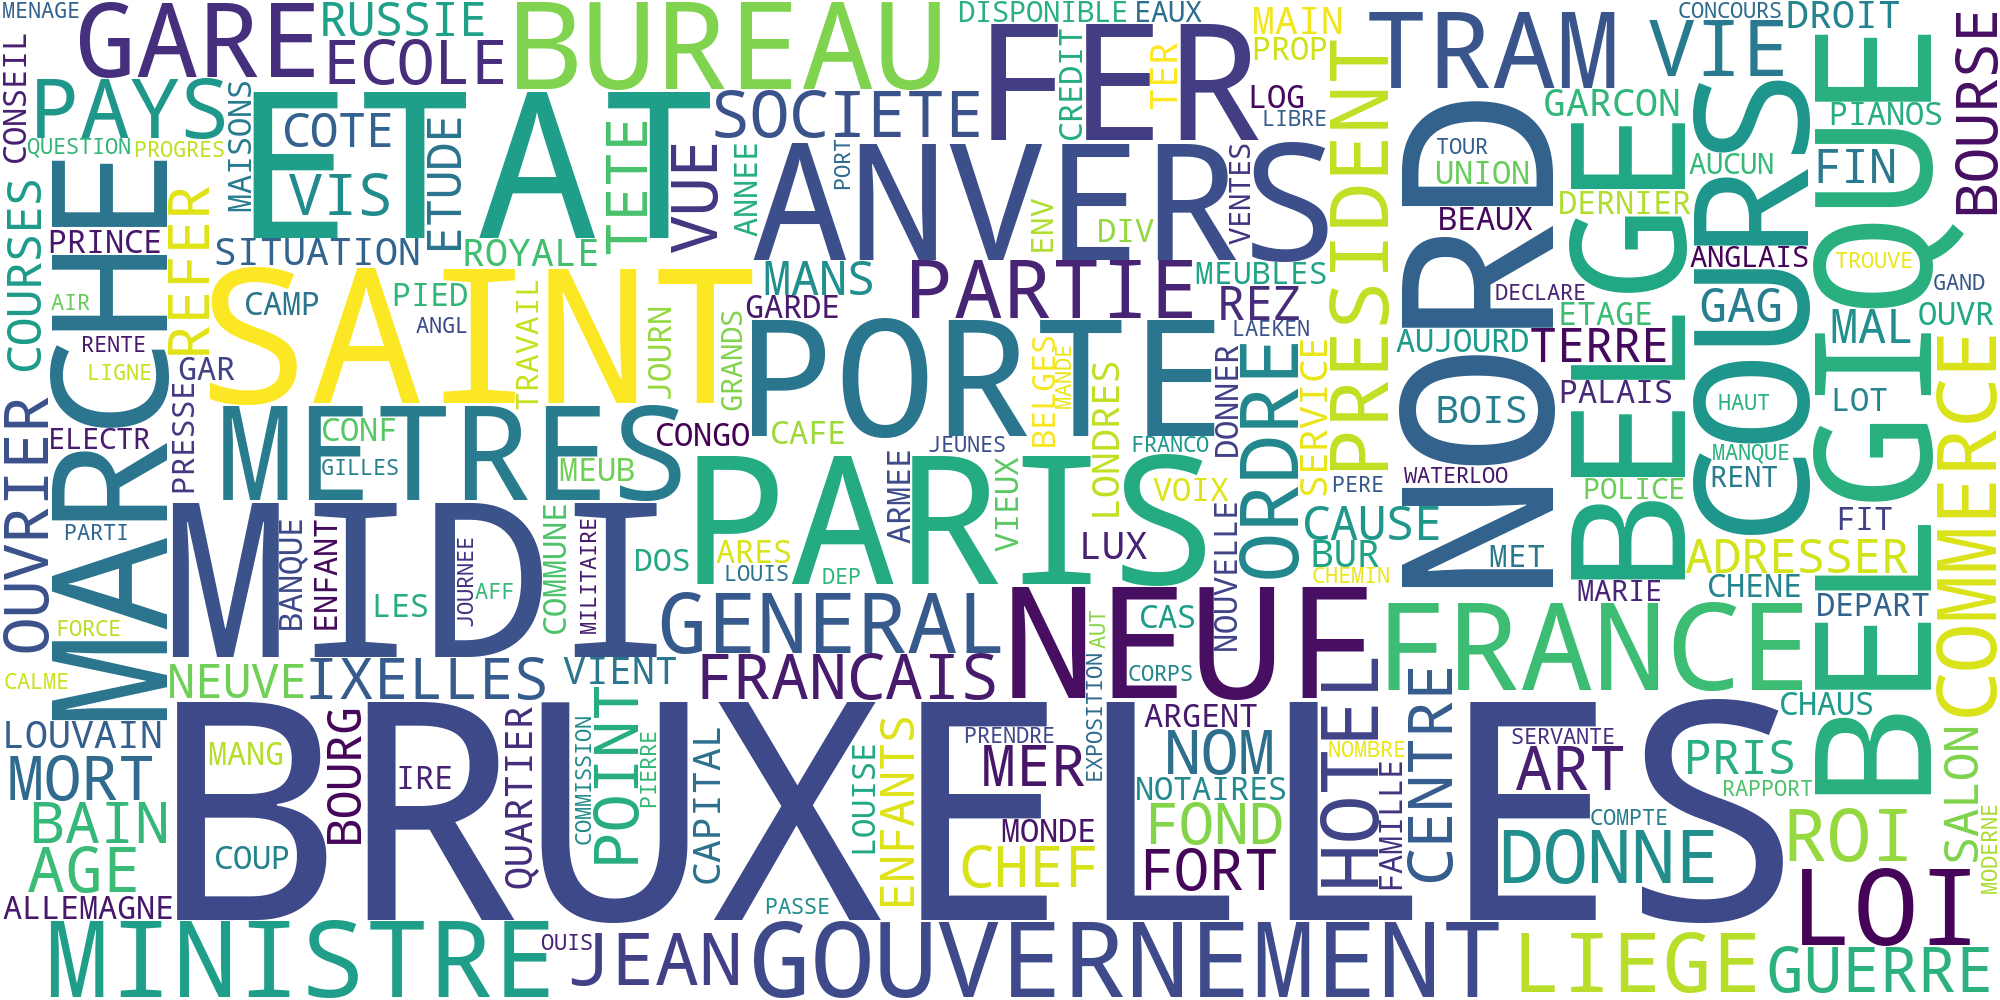

In [203]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))